In [2]:
# # FINAURA – NSE Stocks Data Preprocessing

# This notebook performs complete preprocessing of the NSE stock dataset used in the FINAURA project.

# ## Stocks Included
# - RELIANCE
# - TCS
# - INFY
# - HDFCBANK
# - ICICIBANK
# - ITC
# - SBIN
# - LT

# ## Preprocessing Steps
# 1. Data Loading
# 2. Data Inspection
# 3. Data Type Conversion
# 4. Missing Value Analysis
# 5. Duplicate Analysis
# 6. Symbol-wise Sorting
# 7. OHLC Validation
# 8. Return Calculation
# 9. Technical Feature Engineering
# 10. Volatility Calculation
# 11. Momentum and Drawdown
# 12. Next 5-Day Volatility Target
# 13. Leakage Check
# 14. Final Validation
# 15. Export Processed Dataset

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

In [4]:
BASE_DIR = Path.cwd().parent

INPUT_FILE = BASE_DIR / "data" / "raw" / "nse_stocks_raw.csv"
OUTPUT_FILE = BASE_DIR / "data" / "processed" / "nse_stocks_processed.csv"

print("Input file:", INPUT_FILE)
print("Output file:", OUTPUT_FILE)

Input file: c:\Users\madhu\OneDrive\Documents\FINAURA\data\raw\nse_stocks_raw.csv
Output file: c:\Users\madhu\OneDrive\Documents\FINAURA\data\processed\nse_stocks_processed.csv


In [5]:
df = pd.read_csv(INPUT_FILE)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Dataset loaded successfully!
Rows: 19144
Columns: 8


,Date,Symbol,Open,High,Low,Close,Adj Close,Volume
0,2017-01-02,RELIANCE,247.7842,249.1557,245.1212,248.0356,236.6767,7097888
1,2017-01-03,RELIANCE,249.1214,250.7558,247.1213,249.0185,237.6146,6434204
2,2017-01-04,RELIANCE,249.8186,249.8414,243.2811,243.9325,232.7616,10392483
3,2017-01-05,RELIANCE,244.8126,246.8470,244.2983,246.2755,234.9972,8734164
4,2017-01-06,RELIANCE,245.5441,248.0128,245.2926,245.7155,234.4628,7845839


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19144 entries, 0 to 19143
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       19144 non-null  object 
 1   Symbol     19144 non-null  object 
 2   Open       19144 non-null  float64
 3   High       19144 non-null  float64
 4   Low        19144 non-null  float64
 5   Close      19144 non-null  float64
 6   Adj Close  19144 non-null  float64
 7   Volume     19144 non-null  int64  
dtypes: float64(5), int64(1), object(2)
memory usage: 1.2+ MB


In [7]:
df.describe()

,Open,High,Low,Close,Adj Close,Volume
count,19144.0000,19144.0000,19144.0000,19144.0000,19144.0000,19144.0000
mean,1162.8630,1174.0875,1151.0109,1162.3015,1078.5431,14199501.5606
std,981.1611,989.8102,971.8612,980.6143,922.6464,16613423.8695
min,142.5115,146.3631,129.6084,141.7893,104.3902,0.0000
25%,443.7188,449.2495,438.5958,444.3718,401.4332,4397122.5000
50%,830.5000,838.1500,823.1000,830.7625,797.6707,10165834.0000
75%,1439.7000,1450.0000,1426.1250,1437.0250,1368.6038,17817238.7500
max,4576.0000,4592.2500,4512.0000,4553.7500,4375.3643,445342100.0000


In [8]:
print("Number of stocks:", df["Symbol"].nunique())

print("\nStocks present:")
print(df["Symbol"].unique())

Number of stocks: 8

Stocks present:
['RELIANCE' 'TCS' 'INFY' 'HDFCBANK' 'ICICIBANK' 'ITC' 'SBIN' 'LT']


In [9]:
stock_counts = (
    df["Symbol"]
    .value_counts()
    .sort_index()
)

stock_counts

Symbol
HDFCBANK     2393
ICICIBANK    2393
INFY         2393
ITC          2393
LT           2393
RELIANCE     2393
SBIN         2393
TCS          2393
Name: count, dtype: int64

In [10]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print(df.columns.tolist())

['date', 'symbol', 'open', 'high', 'low', 'close', 'adj_close', 'volume']


In [11]:
df["date"] = pd.to_datetime(
    df["date"],
    errors="coerce"
)

print("Date datatype:", df["date"].dtype)

Date datatype: datetime64[ns]


In [12]:
numeric_columns = [
    "open",
    "high",
    "low",
    "close",
    "adj_close",
    "volume"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19144 entries, 0 to 19143
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   date       19144 non-null  datetime64[ns]
 1   symbol     19144 non-null  object        
 2   open       19144 non-null  float64       
 3   high       19144 non-null  float64       
 4   low        19144 non-null  float64       
 5   close      19144 non-null  float64       
 6   adj_close  19144 non-null  float64       
 7   volume     19144 non-null  int64         
dtypes: datetime64[ns](1), float64(5), int64(1), object(1)
memory usage: 1.2+ MB


In [13]:
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

missing

,Missing_Count,Missing_Percentage
date,0,0.0000
symbol,0,0.0000
open,0,0.0000
high,0,0.0000
low,0,0.0000
close,0,0.0000
adj_close,0,0.0000
volume,0,0.0000


In [14]:
print("Duplicate rows:", df.duplicated().sum())

print(
    "Duplicate stock-date records:",
    df.duplicated(
        subset=["symbol", "date"]
    ).sum()
)

Duplicate rows: 0
Duplicate stock-date records: 0


In [15]:
df = df.drop_duplicates()

df = df.drop_duplicates(
    subset=["symbol", "date"],
    keep="first"
)

print(
    "Rows after duplicate removal:",
    len(df)
)

Rows after duplicate removal: 19144


In [16]:
print(
    "Invalid dates:",
    df["date"].isna().sum()
)

Invalid dates: 0


In [17]:
df = df.sort_values(
    ["symbol", "date"]
).reset_index(drop=True)

df.head(10)

,date,symbol,open,high,low,close,adj_close,volume
0,2017-01-02,HDFCBANK,302.3625,302.5250,298.0125,299.2750,272.9474,3708656
1,2017-01-03,HDFCBANK,300.2000,300.4875,296.4375,297.4750,271.3058,3847500
2,2017-01-04,HDFCBANK,297.4625,298.0000,295.9500,296.3750,270.3026,6967120
3,2017-01-05,HDFCBANK,297.2500,298.6250,295.7750,296.5500,270.4621,6776384
4,2017-01-06,HDFCBANK,297.5250,299.6000,297.0500,298.4125,272.1609,5525260
5,2017-01-09,HDFCBANK,299.7125,301.0375,298.0375,298.8000,272.5143,4573796
6,2017-01-10,HDFCBANK,299.0500,304.2000,298.8250,303.5875,276.8806,5546116
7,2017-01-11,HDFCBANK,304.3750,309.5250,303.8750,308.5000,281.3609,9343404
8,2017-01-12,HDFCBANK,308.7500,310.9250,306.3750,308.7500,281.5889,2916316
9,2017-01-13,HDFCBANK,309.7500,309.9250,307.1500,308.1250,281.0189,3850412


In [18]:
date_ranges = (
    df.groupby("symbol")["date"]
    .agg(["min", "max"])
)

date_ranges

,min,max
symbol,,
HDFCBANK,2017-01-02,2026-09-02
ICICIBANK,2017-01-02,2026-09-02
INFY,2017-01-02,2026-09-02
ITC,2017-01-02,2026-09-02
LT,2017-01-02,2026-09-02
RELIANCE,2017-01-02,2026-09-02
SBIN,2017-01-02,2026-09-02
TCS,2017-01-02,2026-09-02


In [19]:
core_columns = [
    "open",
    "high",
    "low",
    "close"
]

print(
    df[core_columns]
    .isnull()
    .sum()
)

open     0
high     0
low      0
close    0
dtype: int64


In [20]:
df = df.dropna(
    subset=core_columns
)

print(
    "Rows remaining:",
    len(df)
)

Rows remaining: 19144


In [21]:
for col in core_columns:

    invalid = (
        df[col] <= 0
    ).sum()

    print(
        f"{col}: {invalid} invalid values"
    )

open: 0 invalid values
high: 0 invalid values
low: 0 invalid values
close: 0 invalid values


In [22]:
invalid_ohlc = (
    (df["high"] < df["open"]) |
    (df["high"] < df["close"]) |
    (df["low"] > df["open"]) |
    (df["low"] > df["close"]) |
    (df["high"] < df["low"])
)

print(
    "Invalid OHLC rows:",
    invalid_ohlc.sum()
)

Invalid OHLC rows: 0


In [23]:
df = df[
    ~invalid_ohlc
].copy()

print(
    "Rows after OHLC validation:",
    len(df)
)

Rows after OHLC validation: 19144


In [24]:
print(
    "Negative volume:",
    (df["volume"] < 0).sum()
)

Negative volume: 0


In [25]:
df["daily_return"] = (
    df.groupby("symbol")["close"]
    .pct_change()
)

df[
    [
        "symbol",
        "date",
        "close",
        "daily_return"
    ]
].head(15)

,symbol,date,close,daily_return
0,HDFCBANK,2017-01-02,299.2750,NaN
1,HDFCBANK,2017-01-03,297.4750,-0.0060
2,HDFCBANK,2017-01-04,296.3750,-0.0037
3,HDFCBANK,2017-01-05,296.5500,0.0006
4,HDFCBANK,2017-01-06,298.4125,0.0063
5,HDFCBANK,2017-01-09,298.8000,0.0013
6,HDFCBANK,2017-01-10,303.5875,0.0160
7,HDFCBANK,2017-01-11,308.5000,0.0162
8,HDFCBANK,2017-01-12,308.7500,0.0008
9,HDFCBANK,2017-01-13,308.1250,-0.0020


In [26]:
df["log_return"] = (
    df.groupby("symbol")["close"]
    .transform(
        lambda x: np.log(
            x / x.shift(1)
        )
    )
)

df[
    [
        "symbol",
        "date",
        "close",
        "log_return"
    ]
].head(15)

,symbol,date,close,log_return
0,HDFCBANK,2017-01-02,299.2750,NaN
1,HDFCBANK,2017-01-03,297.4750,-0.0060
2,HDFCBANK,2017-01-04,296.3750,-0.0037
3,HDFCBANK,2017-01-05,296.5500,0.0006
4,HDFCBANK,2017-01-06,298.4125,0.0063
5,HDFCBANK,2017-01-09,298.8000,0.0013
6,HDFCBANK,2017-01-10,303.5875,0.0159
7,HDFCBANK,2017-01-11,308.5000,0.0161
8,HDFCBANK,2017-01-12,308.7500,0.0008
9,HDFCBANK,2017-01-13,308.1250,-0.0020


In [27]:
df["intraday_return"] = (
    (df["close"] - df["open"])
    / df["open"]
)

df[
    [
        "symbol",
        "date",
        "intraday_return"
    ]
].head()

,symbol,date,intraday_return
0,HDFCBANK,2017-01-02,-0.0102
1,HDFCBANK,2017-01-03,-0.0091
2,HDFCBANK,2017-01-04,-0.0037
3,HDFCBANK,2017-01-05,-0.0024
4,HDFCBANK,2017-01-06,0.0030


In [28]:
df["price_range"] = (
    (df["high"] - df["low"])
    / df["close"]
)

df[
    [
        "symbol",
        "date",
        "price_range"
    ]
].head()

,symbol,date,price_range
0,HDFCBANK,2017-01-02,0.0151
1,HDFCBANK,2017-01-03,0.0136
2,HDFCBANK,2017-01-04,0.0069
3,HDFCBANK,2017-01-05,0.0096
4,HDFCBANK,2017-01-06,0.0085


In [29]:
for window in [5, 10, 20, 50]:

    df[f"ma_{window}"] = (
        df.groupby("symbol")["close"]
        .transform(
            lambda x:
            x.rolling(window).mean()
        )
    )

In [30]:
for window in [5, 10, 20]:

    df[f"volatility_{window}d"] = (
        df.groupby("symbol")["log_return"]
        .transform(
            lambda x:
            x.rolling(window).std()
            * np.sqrt(252)
        )
    )

In [31]:
df[
    [
        "symbol",
        "date",
        "volatility_5d",
        "volatility_10d",
        "volatility_20d"
    ]
].tail(10)

,symbol,date,volatility_5d,volatility_10d,volatility_20d
19134,TCS,2026-08-20,0.1732,0.3170,0.3606
19135,TCS,2026-08-21,0.1833,0.2483,0.3603
19136,TCS,2026-08-24,0.1309,0.2471,0.3557
19137,TCS,2026-08-25,0.0843,0.2428,0.3169
19138,TCS,2026-08-26,0.1191,0.1598,0.3072
19139,TCS,2026-08-27,0.1177,0.1408,0.3078
19140,TCS,2026-08-28,0.3474,0.2714,0.3327
19141,TCS,2026-08-31,0.3563,0.2734,0.3023
19142,TCS,2026-09-01,0.3919,0.2703,0.3046
19143,TCS,2026-09-02,0.3849,0.2777,0.2990


In [32]:
df["momentum_5d"] = (
    df.groupby("symbol")["close"]
    .transform(
        lambda x:
        x / x.shift(5) - 1
    )
)

df["momentum_20d"] = (
    df.groupby("symbol")["close"]
    .transform(
        lambda x:
        x / x.shift(20) - 1
    )
)

df[
    [
        "symbol",
        "date",
        "momentum_5d",
        "momentum_20d"
    ]
].tail()

,symbol,date,momentum_5d,momentum_20d
19139,TCS,2026-08-27,-0.0216,-0.0754
19140,TCS,2026-08-28,0.0174,-0.0100
19141,TCS,2026-08-31,0.0504,-0.0301
19142,TCS,2026-09-01,0.0317,-0.0370
19143,TCS,2026-09-02,0.0344,-0.0269


In [33]:
df["running_max"] = (
    df.groupby("symbol")["close"]
    .cummax()
)

df["drawdown"] = (
    df["close"] /
    df["running_max"] - 1
)

df.drop(
    columns=["running_max"],
    inplace=True
)

df[
    [
        "symbol",
        "date",
        "close",
        "drawdown"
    ]
].tail()

,symbol,date,close,drawdown
19139,TCS,2026-08-27,2248.3999,-0.5063
19140,TCS,2026-08-28,2342.0000,-0.4857
19141,TCS,2026-08-31,2399.3000,-0.4731
19142,TCS,2026-09-01,2369.0000,-0.4798
19143,TCS,2026-09-02,2348.0000,-0.4844


In [34]:
df["volume_ma_20"] = (
    df.groupby("symbol")["volume"]
    .transform(
        lambda x:
        x.rolling(20).mean()
    )
)

df["volume_ratio"] = (
    df["volume"] /
    df["volume_ma_20"]
)

df[
    [
        "symbol",
        "date",
        "volume",
        "volume_ma_20",
        "volume_ratio"
    ]
].tail()

,symbol,date,volume,volume_ma_20,volume_ratio
19139,TCS,2026-08-27,1709113,2757621.5500,0.6198
19140,TCS,2026-08-28,4054069,2743140.8500,1.4779
19141,TCS,2026-08-31,2905846,2736591.2000,1.0618
19142,TCS,2026-09-01,2678034,2730853.3000,0.9807
19143,TCS,2026-09-02,2533005,2706783.1000,0.9358


In [35]:

# Calculate returns for the next 5 trading days
future_returns = pd.concat(
    [
        df.groupby("symbol")["log_return"].shift(-i)
        .rename(f"future_return_{i}")
        for i in range(1, 6)
    ],
    axis=1
)

# Keep only rows having all 5 future returns
complete_future = future_returns.notna().all(axis=1)

df["target_5d_volatility"] = (
    future_returns.std(axis=1)
    * np.sqrt(252)
).where(complete_future)

df[
    ["symbol", "date", "target_5d_volatility"]
].tail(10)


,symbol,date,target_5d_volatility
19134,TCS,2026-08-20,0.1177
19135,TCS,2026-08-21,0.3474
19136,TCS,2026-08-24,0.3563
19137,TCS,2026-08-25,0.3919
19138,TCS,2026-08-26,0.3849
19139,TCS,2026-08-27,NaN
19140,TCS,2026-08-28,NaN
19141,TCS,2026-08-31,NaN
19142,TCS,2026-09-01,NaN
19143,TCS,2026-09-02,NaN


In [36]:
df[
    [
        "symbol",
        "date",
        "volatility_20d",
        "target_5d_volatility"
    ]
].tail(10)

,symbol,date,volatility_20d,target_5d_volatility
19134,TCS,2026-08-20,0.3606,0.1177
19135,TCS,2026-08-21,0.3603,0.3474
19136,TCS,2026-08-24,0.3557,0.3563
19137,TCS,2026-08-25,0.3169,0.3919
19138,TCS,2026-08-26,0.3072,0.3849
19139,TCS,2026-08-27,0.3078,NaN
19140,TCS,2026-08-28,0.3327,NaN
19141,TCS,2026-08-31,0.3023,NaN
19142,TCS,2026-09-01,0.3046,NaN
19143,TCS,2026-09-02,0.2990,NaN


In [37]:
target = "target_5d_volatility"

feature_columns = [
    "open",
    "high",
    "low",
    "close",
    "volume",
    "daily_return",
    "log_return",
    "intraday_return",
    "price_range",
    "ma_5",
    "ma_10",
    "ma_20",
    "ma_50",
    "volatility_5d",
    "volatility_10d",
    "volatility_20d",
    "momentum_5d",
    "momentum_20d",
    "drawdown",
    "volume_ma_20",
    "volume_ratio"
]

print("Number of features:", len(feature_columns))
print("Target:", target)

print(
    "Target included in features:",
    target in feature_columns
)

Number of features: 21
Target: target_5d_volatility
Target included in features: False


In [38]:
print(
    "Missing values before final cleaning:",
    df.isnull().sum().sum()
)

Missing values before final cleaning: 1488


In [39]:
df = df.dropna().reset_index(drop=True)

print(
    "Missing values after final cleaning:",
    df.isnull().sum().sum()
)

Missing values after final cleaning: 0


In [40]:
print("========== FINAL DATASET ==========")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print(
    "Start date:",
    df["date"].min()
)

print(
    "End date:",
    df["date"].max()
)

print(
    "Number of stocks:",
    df["symbol"].nunique()
)

print(
    "Missing values:",
    df.isnull().sum().sum()
)

print(
    "Duplicate rows:",
    df.duplicated().sum()
)

print(
    "Duplicate stock-date:",
    df.duplicated(
        subset=["symbol", "date"]
    ).sum()
)

========== FINAL DATASET ==========
Rows: 18712
Columns: 25
Start date: 2017-03-15 00:00:00
End date: 2026-08-26 00:00:00
Number of stocks: 8
Missing values: 0
Duplicate rows: 0
Duplicate stock-date: 0


In [41]:
final_counts = (
    df.groupby("symbol")
    .size()
    .sort_values(
        ascending=False
    )
)

final_counts

symbol
HDFCBANK     2339
ICICIBANK    2339
INFY         2339
ITC          2339
LT           2339
RELIANCE     2339
SBIN         2339
TCS          2339
dtype: int64

In [42]:
for i, col in enumerate(
    df.columns,
    1
):
    print(i, "-", col)

1 - date
2 - symbol
3 - open
4 - high
5 - low
6 - close
7 - adj_close
8 - volume
9 - daily_return
10 - log_return
11 - intraday_return
12 - price_range
13 - ma_5
14 - ma_10
15 - ma_20
16 - ma_50
17 - volatility_5d
18 - volatility_10d
19 - volatility_20d
20 - momentum_5d
21 - momentum_20d
22 - drawdown
23 - volume_ma_20
24 - volume_ratio
25 - target_5d_volatility


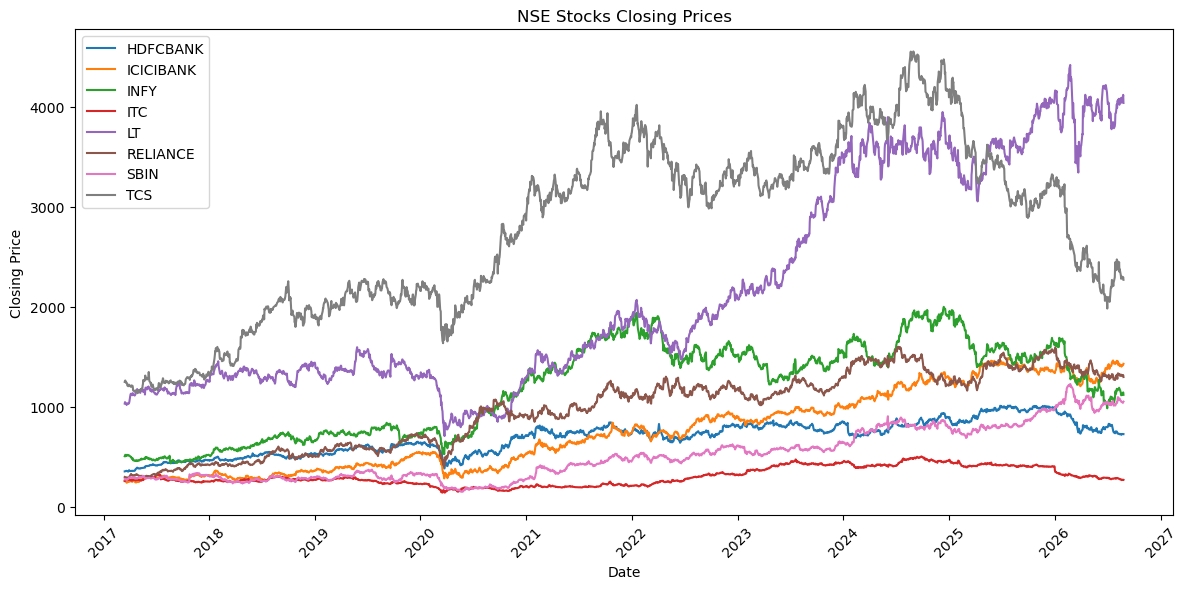

In [43]:
plt.figure(figsize=(12, 6))

for symbol in df["symbol"].unique():

    stock_data = df[
        df["symbol"] == symbol
    ]

    plt.plot(
        stock_data["date"],
        stock_data["close"],
        label=symbol
    )

plt.title("NSE Stocks Closing Prices")
plt.xlabel("Date")
plt.ylabel("Closing Price")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

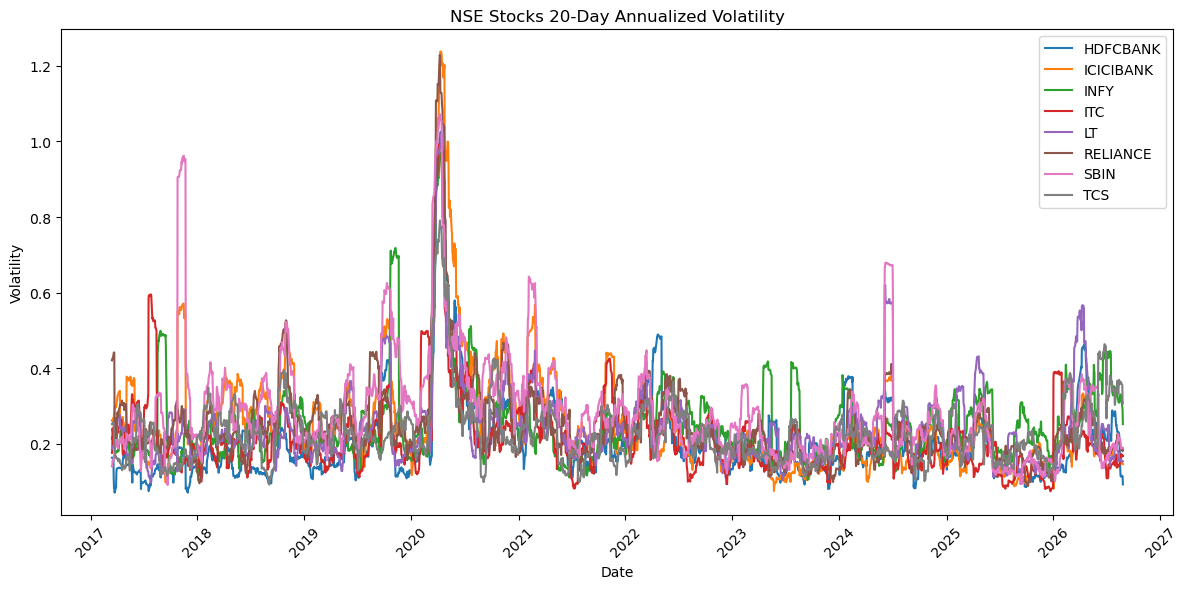

In [44]:
plt.figure(figsize=(12, 6))

for symbol in df["symbol"].unique():

    stock_data = df[
        df["symbol"] == symbol
    ]

    plt.plot(
        stock_data["date"],
        stock_data["volatility_20d"],
        label=symbol
    )

plt.title("NSE Stocks 20-Day Annualized Volatility")
plt.xlabel("Date")
plt.ylabel("Volatility")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [45]:
OUTPUT_FILE.parent.mkdir(
    parents=True,
    exist_ok=True
)

df.to_csv(
    OUTPUT_FILE,
    index=False
)

print("Processed NSE stocks dataset saved successfully!")
print("Location:", OUTPUT_FILE)
print("Rows:", len(df))
print("Columns:", len(df.columns))

Processed NSE stocks dataset saved successfully!
Location: c:\Users\madhu\OneDrive\Documents\FINAURA\data\processed\nse_stocks_processed.csv
Rows: 18712
Columns: 25
